# 01 Â· GeraÃ§Ã£o do banco de dados sintÃ©tico â€” Boto CafÃ© â˜•ðŸ¬

**Objetivo:** criar, com Python, o banco de dados de uma loja online **fictÃ­cia** de cafÃ© especial
(2.000 clientes, ~16 mil pedidos, 24 meses), com comportamentos realistas e algumas sujeiras
propositais para treinarmos limpeza e anÃ¡lise.

> **Analogia:** pense neste notebook como um **teatro**. Primeiro escrevemos o *roteiro* de cada personagem
> (o perfil: VIP, fiel, em risco...). Depois deixamos cada um "atuar" durante 24 meses, comprando cafÃ©.
> Na Fase 2, a anÃ¡lise RFM vai tentar descobrir quem Ã© quem **sem ler o roteiro** â€” e nÃ³s conferimos se ela acertou.

Todo o cÃ³digo pesado estÃ¡ em `src/` (reutilizÃ¡vel); o notebook sÃ³ **conta a histÃ³ria**.

In [1]:
import sys
from pathlib import Path

# Permite importar o pacote `src` mesmo rodando o notebook de dentro de /notebooks
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt

from src import banco, config as cfg, gerador, validacao
from src.catalogo import ESTADOS

# Paleta da marca Boto CafÃ© (usada em todos os grÃ¡ficos do projeto)
CAFE, ROSA, VERDE, CREME, OURO = "#3E2723", "#E8A0B4", "#2E5E4E", "#F5EDE0", "#C8963E"
plt.rcParams.update({"figure.facecolor": "white", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Os parÃ¢metros do experimento
**Por que uma seed fixa?** `SEED = 42` faz o gerador sortear *sempre* os mesmos nÃºmeros.
Sem isso, cada execuÃ§Ã£o geraria uma loja diferente e seus resultados (e prints do portfÃ³lio) nÃ£o bateriam mais.
Pelo mesmo motivo a data final Ã© **fixa** (07/10/2026) em vez de "hoje".

In [2]:
print(f"Seed ........: {cfg.SEED}")
print(f"Clientes ....: {cfg.N_CLIENTES:,}")
print(f"Janela ......: {cfg.DATA_INICIO:%d/%m/%Y} â†’ {cfg.DATA_FIM:%d/%m/%Y} ({cfg.JANELA_DIAS} dias)")

Seed ........: 42
Clientes ....: 2,000
Janela ......: 07/10/2024 â†’ 07/10/2026 (730 dias)


## 2. Os perfis comportamentais (o "roteiro")
Cada perfil muda **quando** o cliente se cadastra, **quantas vezes** compra, **quando para** de comprar,
**quanto** gasta e **se depende de cupom**. Ã‰ isso que cria padrÃµes reais para o RFM descobrir.

In [3]:
perfis = pd.DataFrame(gerador.PERFIS).T[["prop", "media", "minimo", "parada", "cupom"]]
perfis.columns = ["% dos clientes", "pedidos (mÃ©dia)", "pedidos (mÃ­n.)", "para de comprar hÃ¡ (dias)", "usa cupom (prob.)"]
perfis

,% dos clientes,pedidos (mÃ©dia),pedidos (mÃ­n.),para de comprar hÃ¡ (dias),usa cupom (prob.)
vip,0.05,40,24,None,0.25
fiel,0.15,15,8,None,0.50
ocasional,0.30,3.50,1,None,0.60
novo,0.12,1.80,1,None,0.55
em_risco,0.12,6,4,"(100, 200)",0.50
perdido,0.18,3,1,"(300, 560)",0.60
cacador,0.08,9,5,None,0.95


**Sazonalidade embutida:** cada dia da janela recebe um *peso de demanda*. Black Friday pesa 4â€“6Ã—,
a corrida de Natal (1â€“22/dez) 2Ã—, e os 10 dias antes do Dia dos Pais 2,5Ã—. HÃ¡ ainda uma tendÃªncia de
crescimento (~30% em 24 meses), fins de semana um pouco mais fortes e produtos sazonais
(Kit Dia dos Pais, Kit Natal) que sÃ³ vendem na Ã©poca certa.

## 3. Gerando e gravando tudo

In [4]:
dados = gerador.gerar_tudo()          # gera as 4 tabelas + gabarito (em memÃ³ria)
banco.salvar_sqlite(dados)            # grava data/loja.db com chaves e regras CHECK
banco.exportar_csvs(dados)            # grava data/raw/*.csv

for tabela in banco.TABELAS:
    print(f"{tabela:<14} {len(dados[tabela]):>7,} linhas")

clientes         2,000 linhas
produtos            40 linhas
pedidos         15,882 linhas
itens_pedido    32,813 linhas


**DecisÃ£o: por que declarar o esquema (DDL) em vez de deixar o pandas criar as tabelas?**
Assim o banco tem *chaves primÃ¡rias, estrangeiras e regras `CHECK`* (ex.: preÃ§o > 0, status sÃ³ dos valores permitidos).
Ã‰ como ter um porteiro: dado ruim nem entra. Em Analytics Engineering isso Ã© o dia a dia.

In [5]:
dados['clientes'].head()

,id,nome,email,cidade,estado,data_cadastro,canal_aquisicao
0,1,Sophie Alves Gonçalves,sophiealvesgoncalves@example.com,ananindeua,PA,2024-10-07,Google
1,2,Gael Henrique Rodrigues Freitas,gael.henrique.rodrigues.freitas@example.com,Recife,PE,2024-10-07,Google
2,3,Jade Almeida Duarte,jade_almeida_duarte@example.com,Niterói,RJ,2024-10-07,Instagram
3,4,Isabelly Marques da Mata,isabelly.marques.da.mata@example.com,Feira de Santana,BA,2024-10-07,Marketplace
4,5,Bianca Novais Vargas,bianca_novais_vargas@example.com,Belo Horizonte,MG,2024-10-07,TikTok


In [6]:
dados['produtos'].head(8)

,id,nome,categoria,preco,custo
0,1,Cerrado Mineiro Torra Média 250g,Grãos,42.90,19.00
1,2,Matas de Minas Torra Clara 250g,Grãos,46.90,21.00
2,3,Sul de Minas Torra Média 250g,Grãos,39.90,18.00
3,4,Mogiana Torra Escura 250g,Grãos,37.90,17.00
4,5,Cerrado Mineiro Torra Média 1kg,Grãos,139.90,66.00
5,6,Sul de Minas Torra Média 1kg,Grãos,129.90,62.00
6,7,Conilon Capixaba Robusta 250g,Grãos,33.90,15.00
7,8,Microlote Bourbon Amarelo 250g,Grãos,79.90,36.00


In [7]:
dados['pedidos'].head()

,id,cliente_id,data_pedido,status,cupom_usado,desconto,valor_total,canal
0,1,2,2024-10-07,entregue,NaN,0.00,245.19,site
1,2,4,2024-10-07,entregue,BEMVINDO,71.56,644.09,site
2,3,5,2024-10-07,entregue,NaN,0.00,150.85,site
3,4,1,2024-10-08,entregue,BEMVINDO,23.58,212.17,site
4,5,3,2024-10-08,entregue,BEMVINDO,20.74,186.62,site


In [8]:
dados['itens_pedido'].head()

,id,pedido_id,produto_id,quantidade,preco_unitario
0,1,1,17,1,245.19
1,2,2,34,1,235.75
2,3,2,7,1,31.98
3,4,2,38,1,70.66
4,5,2,40,1,377.26


## 4. ValidaÃ§Ã£o de integridade
TrÃªs perguntas que todo engenheiro de dados faz antes de confiar numa base:
1. **Chaves:** todo `cliente_id` de pedido existe em `clientes`? Todo item aponta para um pedido e um produto reais?
2. **Datas:** nenhum pedido antes do cadastro, tudo dentro da janela?
3. **Totais:** `valor_total` = soma(quantidade Ã— preÃ§o) âˆ’ desconto, centavo a centavo?

In [9]:
integridade = validacao.validar_integridade()
integridade

,checagem,ok,violações,detalhe
0,PK única em clientes,True,0,
1,PK única em produtos,True,0,
2,PK única em pedidos,True,0,
3,PK única em itens_pedido,True,0,
4,PRAGMA foreign_key_check,True,0,
5,pedidos.cliente_id existe em clientes,True,0,
6,itens.pedido_id existe em pedidos,True,0,
7,itens.produto_id existe em produtos,True,0,
8,todo pedido tem >= 1 item,True,0,
9,pedidos dentro da janela de 24 meses,True,0,


In [10]:
assert integridade["ok"].all(), "HÃ¡ falhas de integridade!"
print(f"âœ… {len(integridade)} checagens, todas passaram.")

âœ… 17 checagens, todas passaram.


## 5. Sujeiras propositais (seu laboratÃ³rio de limpeza)
Dados reais nunca sÃ£o perfeitos. Deixei imperfeiÃ§Ãµes **controladas** para vocÃª tratar na Fase 2.
A integridade acima prova que a base Ã© *consistente*; a tabela abaixo mostra o que ainda estÃ¡ *sujo*.

In [11]:
validacao.diagnosticar_sujeira()

,problema,qtd
0,e-mails com espaços nas pontas,32
1,e-mails em CAIXA ALTA,58
2,cidades sem acento/minúsculas,68
3,canal_aquisicao nulo,49
4,pedidos cancelados (de 15882),551
5,pedidos devolvidos (de 15882),441
6,pedidos pendentes (em andamento),30


**O que fazer com cada uma (spoiler da Fase 2):**
- *e-mails* â†’ `str.strip().str.lower()`; *cidades* â†’ padronizar usando a tabela de cidades por estado.
- *canal nulo* â†’ marcar como `"NÃ£o informado"` (nunca inventar um canal).
- *cancelados/devolvidos* â†’ **fora** do cÃ¡lculo de RFM (nÃ£o Ã© receita). *Pendentes* tambÃ©m ficam de fora atÃ© serem pagos.

## 6. Conferindo o realismo
NÃ£o basta a base ser consistente â€” ela precisa **parecer** uma loja de verdade.

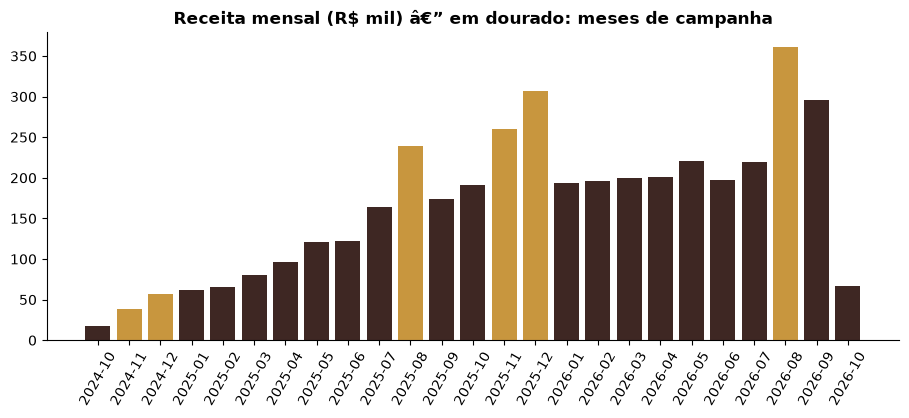

In [12]:
ped = dados["pedidos"].assign(data=lambda d: pd.to_datetime(d["data_pedido"]))
validos = ped[ped["status"].isin(cfg.STATUS_VALIDOS)]
receita_mes = validos.groupby(validos["data"].dt.to_period("M"))["valor_total"].sum()

fig, ax = plt.subplots(figsize=(11, 4))
receita_mes.index = receita_mes.index.astype(str)
cores = [OURO if m in ("2024-11", "2024-12", "2025-08", "2025-11", "2025-12", "2026-08") else CAFE
         for m in receita_mes.index]
ax.bar(receita_mes.index, receita_mes.values / 1000, color=cores)
ax.set_title("Receita mensal (R$ mil) â€” em dourado: meses de campanha")
ax.tick_params(axis="x", rotation=60)
plt.show()

Os picos de **Dia dos Pais (ago/2025 e ago/2026)**, **Black Friday e Natal (novâ€“dez)** aparecem, sobre uma
tendÃªncia de crescimento â€” a loja "nasceu" no comeÃ§o da janela e foi ganhando clientes (por isso o 1Âº mÃªs Ã© pequeno).

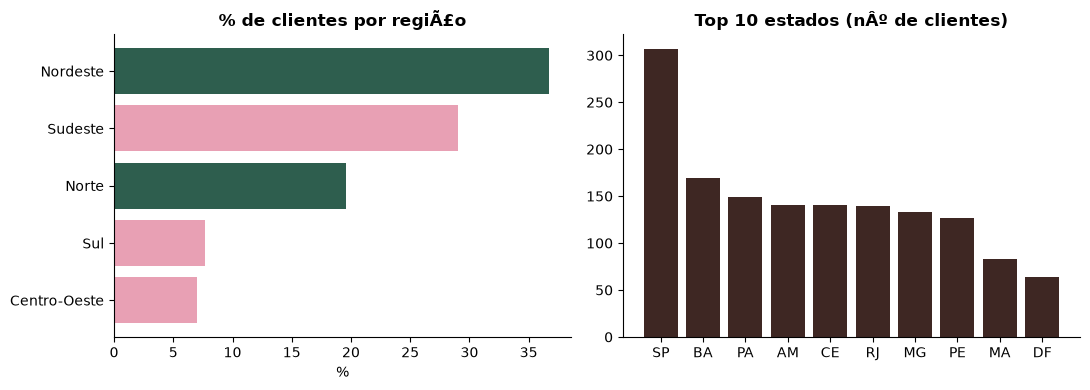

Norte + Nordeste = 56.3% dos clientes


In [13]:
# Geografia: concentraÃ§Ã£o Norte/Nordeste?
regiao = {uf: v[1] for uf, v in ESTADOS.items()}
por_regiao = dados["clientes"]["estado"].map(regiao).value_counts(normalize=True)
por_estado = dados["clientes"]["estado"].value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].barh(por_regiao.index[::-1], por_regiao.values[::-1] * 100,
             color=[VERDE if r in ("Norte", "Nordeste") else ROSA for r in por_regiao.index[::-1]])
axes[0].set_title("% de clientes por regiÃ£o"); axes[0].set_xlabel("%")
axes[1].bar(por_estado.index, por_estado.values, color=CAFE)
axes[1].set_title("Top 10 estados (nÂº de clientes)")
plt.tight_layout(); plt.show()
print(f"Norte + Nordeste = {por_regiao[['Norte', 'Nordeste']].sum():.1%} dos clientes")

In [14]:
# O roteiro vs. o resultado: cada perfil se comporta como esperado?
gab = pd.read_csv(cfg.CAMINHO_GABARITO)
v = validos.merge(gab, on="cliente_id")
resumo = (v.groupby(["cliente_id", "perfil"])
            .agg(ultima=("data", "max"), pedidos=("id", "count"), gasto=("valor_total", "sum"))
            .reset_index())
resumo["dias_sem_comprar"] = (cfg.DATA_FIM - resumo["ultima"]).dt.days
resumo.groupby("perfil").agg(
    clientes=("cliente_id", "count"),
    pedidos_medio=("pedidos", "mean"),
    dias_sem_comprar_mediana=("dias_sem_comprar", "median"),
    gasto_mediano=("gasto", "median"),
    receita_total=("gasto", "sum"),
).sort_values("receita_total", ascending=False)

,clientes,pedidos_medio,dias_sem_comprar_mediana,gasto_mediano,receita_total
perfil,,,,,
vip,100,39.94,7.00,"16,552.04","1,681,692.18"
fiel,300,14.79,14.00,"3,644.14","1,104,921.56"
ocasional,596,3.29,102.00,593.12,"409,161.24"
em_risco,240,6.58,162.00,"1,402.16","370,754.38"
cacador,160,9.19,32.50,"1,767.64","290,060.84"
perdido,355,2.77,450.00,436.23,"193,024.69"
novo,230,1.90,27.50,336.90,"99,677.01"


Repare no padrÃ£o que a Fase 2 vai precisar achar sozinha:
**VIPs** compram ~40 vezes e voltaram hÃ¡ poucos dias; **em risco** compravam bem e sumiram hÃ¡ ~5 meses;
**perdidos** nÃ£o aparecem hÃ¡ mais de um ano; **novos** tÃªm 1â€“2 pedidos recentes.

> âš ï¸ O arquivo `data/gabarito_perfis.csv` Ã© a "resposta da prova". **NÃ£o serÃ¡ usado na anÃ¡lise** â€”
> sÃ³ para conferirmos no final se o RFM acertou.

## 7. EntregÃ¡veis desta fase
| Arquivo | ConteÃºdo |
|---|---|
| `data/loja.db` | Banco SQLite com 4 tabelas, PKs, FKs e CHECKs |
| `data/raw/*.csv` | As mesmas 4 tabelas em CSV |
| `data/gabarito_perfis.csv` | Perfil real de cada cliente (sÃ³ para conferÃªncia) |
| `src/` | CÃ³digo reutilizÃ¡vel (catÃ¡logo, gerador, banco, validaÃ§Ã£o) |

Para regenerar tudo do zero: `python -m src.gerar_dados`